
# Supplementary 03 — External evaluation and robustness

The 884-case retrospective external evaluation and the Phase 36 perturbation
study. Both are read-only analyses of persisted predictions.

Companion to **§10 and §14** of the master notebook.


In [1]:

import sys
from pathlib import Path
sys.path.insert(0, r"D:\Softfors\jup\full_doc_report\Scripts")
import remedfilm_guard as GUARD
GUARD.install()

REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIGURES = REPORT / "figures"

import pandas as pd
import numpy as np
import json
from IPython.display import Image, display

for name, verdict in GUARD.self_test():
    assert verdict.startswith("blocked"), f"GUARD FAILED: {name} {verdict}"
print("analysis-only guard verified")


analysis-only guard verified


In [2]:

ext = pd.read_csv(TABLES / "REMEDFILM_EXTERNAL_METRICS.csv")
dice = ext[ext.metric == "Dice"]
piv = dice.pivot_table(index="cohort", columns="arm",
                       values="mean", aggfunc="first")
piv["delta_FULL_minus_backbone"] = piv["ReMedFiLM_FULL"] - piv["GlobalMedFiLM"]
piv.round(6)


arm,GlobalMedFiLM,ReMedFiLM_FULL,delta_FULL_minus_backbone
cohort,,,
BrEaST-Lesions-USG,0.707822,0.708098,0.000276
CVC-ClinicDB,0.686568,0.689747,0.003180
Stones_where_are_you,0.080840,0.082126,0.001286


In [3]:

print("cohort sizes and denominators")
print(dice.groupby(["cohort", "arm"])[["n_total", "n_defined", "n_clusters"]]
          .first().to_string())
print()
print("No cohort is pooled with another or with VAL808.")


cohort sizes and denominators
                                     n_total  n_defined  n_clusters
cohort               arm                                           
BrEaST-Lesions-USG   GlobalMedFiLM       252        252       252.0
                     ReMedFiLM_FULL      252        252       252.0
CVC-ClinicDB         GlobalMedFiLM       612        612        29.0
                     ReMedFiLM_FULL      612        612        29.0
Stones_where_are_you GlobalMedFiLM        20         20        20.0
                     ReMedFiLM_FULL       20         20        20.0

No cohort is pooled with another or with VAL808.


In [4]:

pc = pd.read_csv(REPO / "reports/tables/c1_external_stress_per_case.csv")
sf = pc[pc.gt_empty.astype(str).str.lower() == "true"]
print("stone-free cases:", len(sf))
if len(sf):
    for arm, grp in sf.groupby("arm"):
        got = (grp.pred_empty.astype(str).str.lower() == "false").sum()
        print(f"  {arm:8s}: {got}/{len(grp)} receive foreground")
print()
print("Preserved negative finding. HD95/ASSD are undefined for empty reference")
print("masks and are reported as missing, not zero.")


stone-free cases: 28
  barr    : 14/14 receive foreground
  global  : 14/14 receive foreground

Preserved negative finding. HD95/ASSD are undefined for empty reference
masks and are reported as missing, not zero.


In [5]:

r36 = json.loads((REPO / "reports/audits/phase36_robustness_scientific_result_v1_23.json")
                 .read_text(encoding="utf-8"))
print("counters")
for k in ("clean_passes", "perturbed_g_forwards", "test_reads", "training",
          "optimizer_steps", "parameter_mutations"):
    print(f"  {k:22s}: {r36['counters'][k]}")
print()
print("clean-equivalence all_pass:", r36["clean_equivalence"]["all_pass"])
print("max |Δ Dice| vs frozen    :", r36["clean_equivalence"].get("max_abs_dice_difference", 0.0))


counters
  clean_passes          : 808
  perturbed_g_forwards  : 12928
  test_reads            : 0
  training              : 0
  optimizer_steps       : 0
  parameter_mutations   : 0

clean-equivalence all_pass: True
max |Δ Dice| vs frozen    : 0.0


In [6]:

rows = r36["image_rows"]
cond = pd.DataFrame(rows).groupby("condition").agg(
    n=("paired_delta_dice", "size"),
    mean_delta=("paired_delta_dice", "mean"),
    min_delta=("paired_delta_dice", "min"),
).sort_values("mean_delta").reset_index()
cond.round(5)


,condition,n,mean_delta,min_delta
0,GAUSSIAN_NOISE_HIGH,2424,-0.15579,-0.92113
1,GAUSSIAN_NOISE_LOW,2424,-0.04286,-0.87407
2,GAUSSIAN_BLUR_HIGH,808,-0.02357,-0.77778
3,RESOLUTION_050,808,-0.02307,-0.77778
4,RESOLUTION_075,808,-0.01361,-0.77778
5,BRIGHTNESS_NEG,808,-0.00765,-0.77698
6,BRIGHTNESS_POS,808,-0.00627,-0.65010
7,GAMMA_LOW,808,-0.00494,-0.50907
8,CONTRAST_LOW,808,-0.00429,-0.36443
9,GAUSSIAN_BLUR_LOW,808,-0.00244,-0.23694


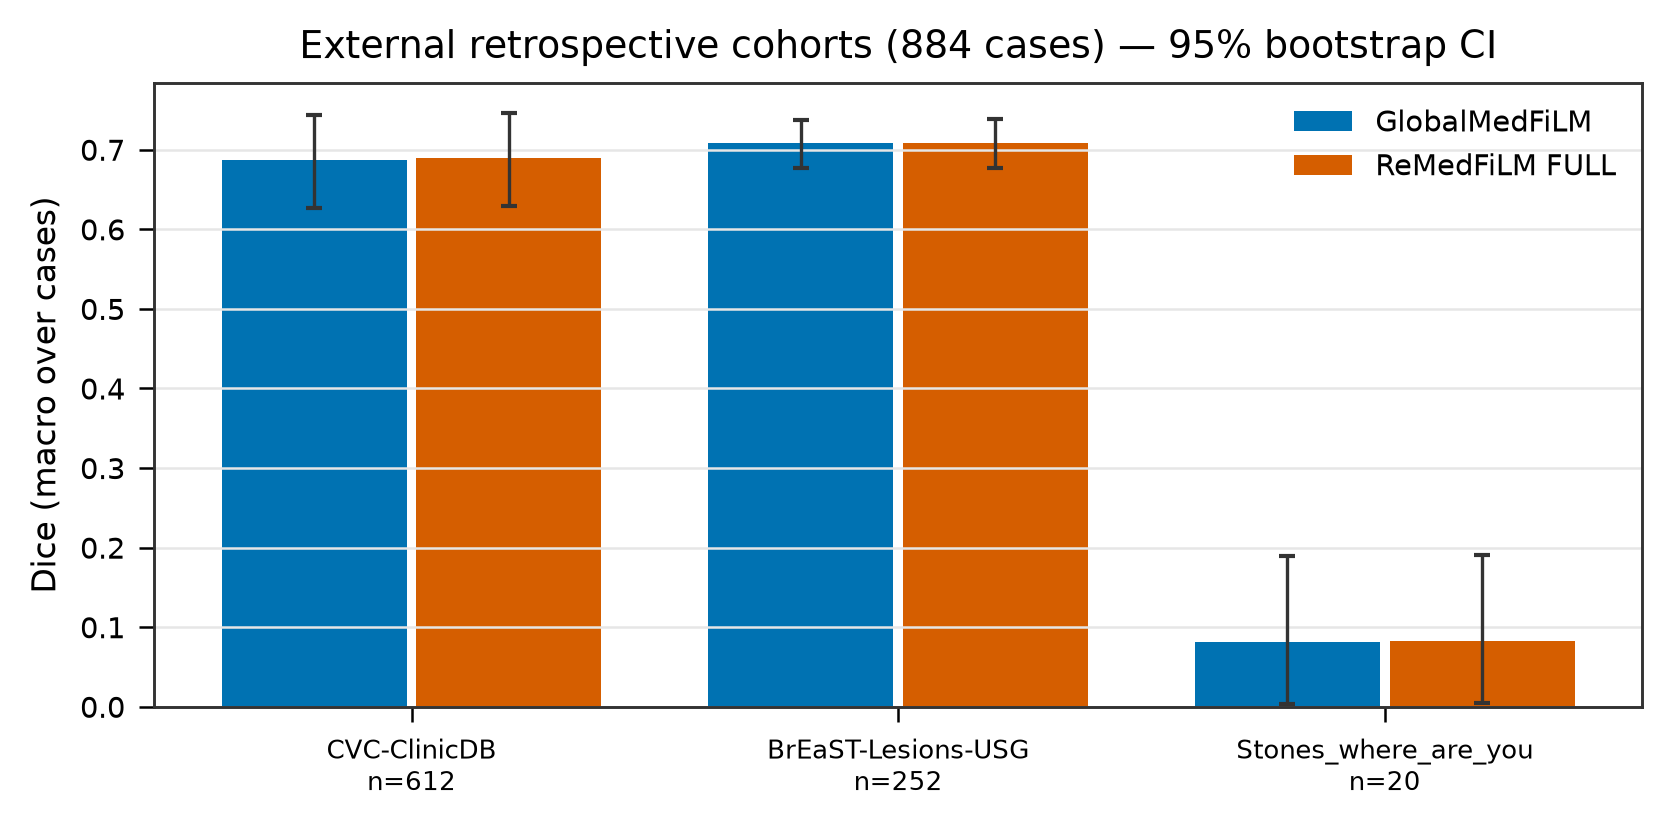

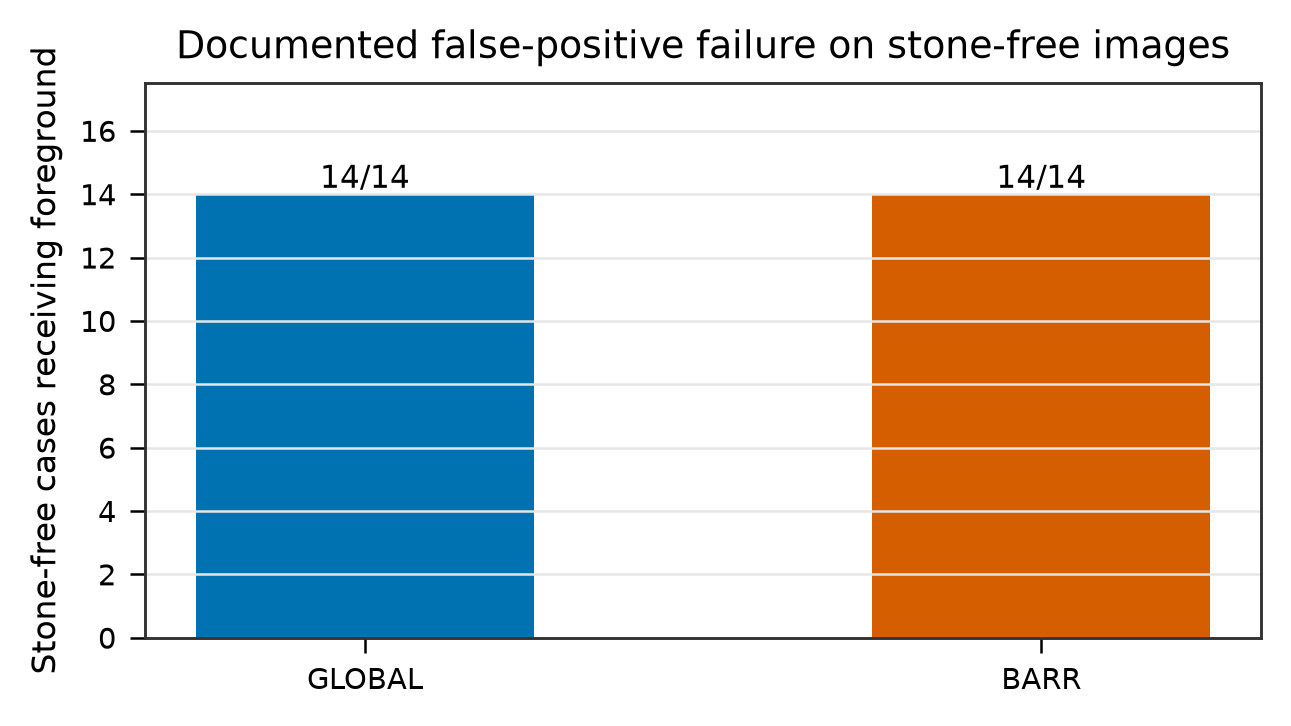

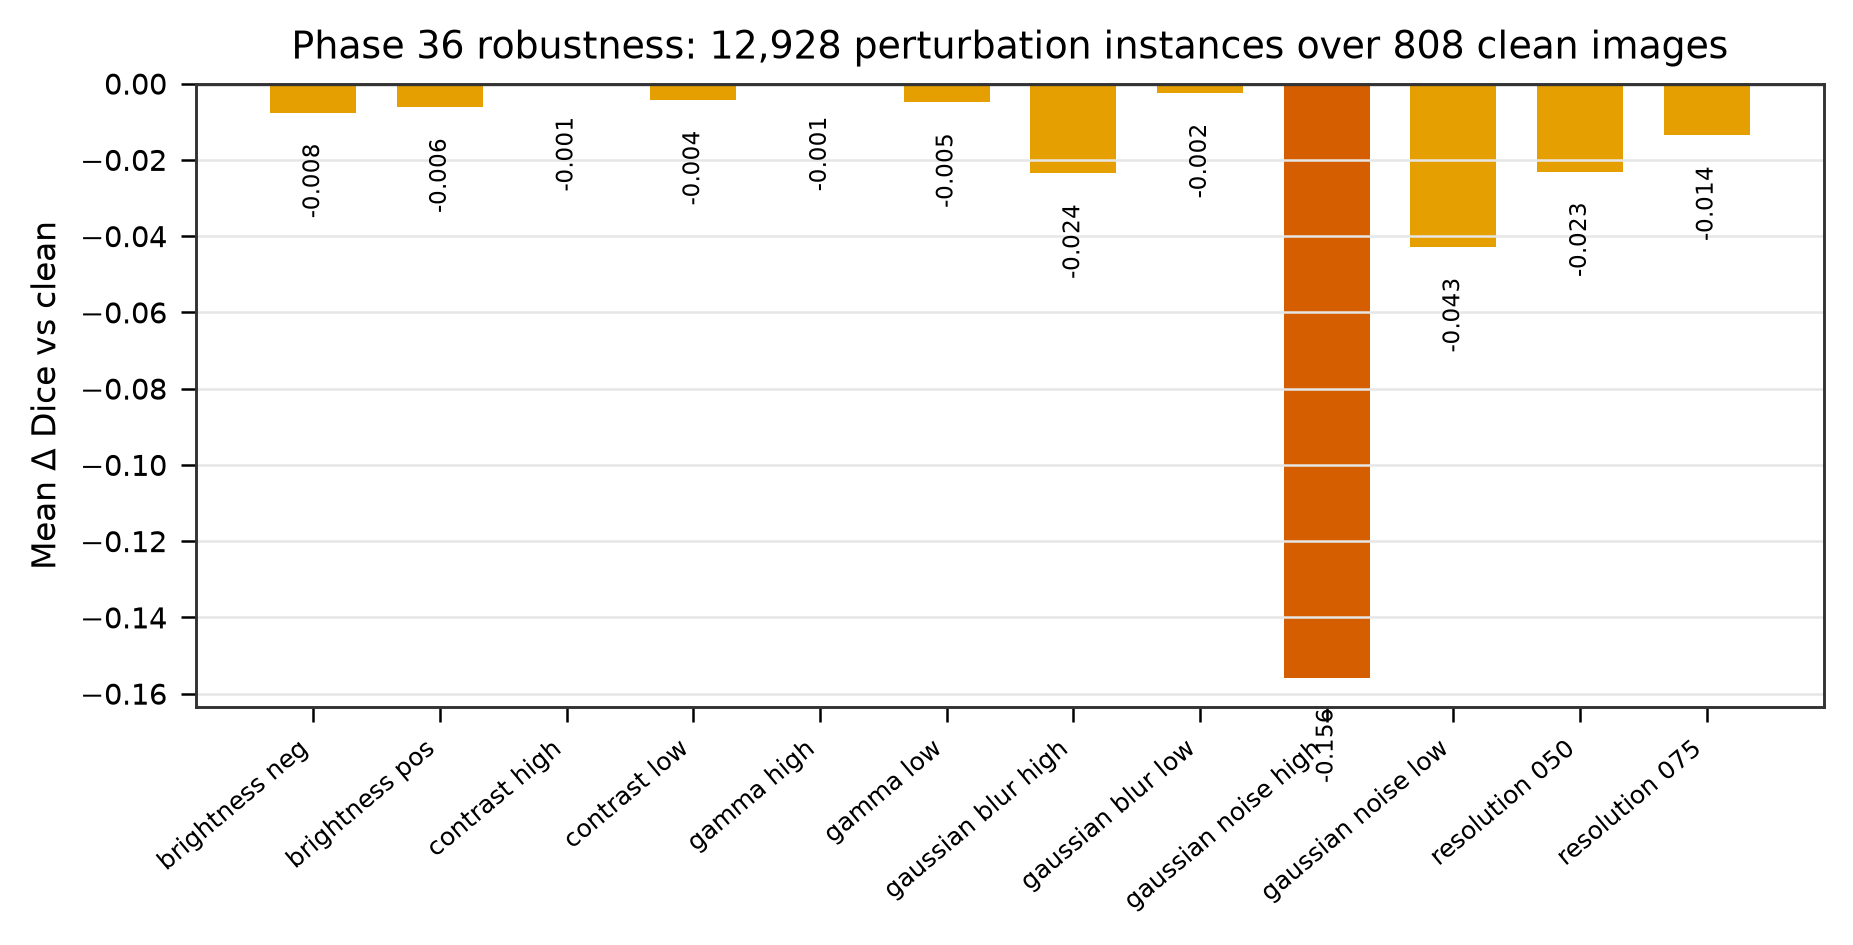

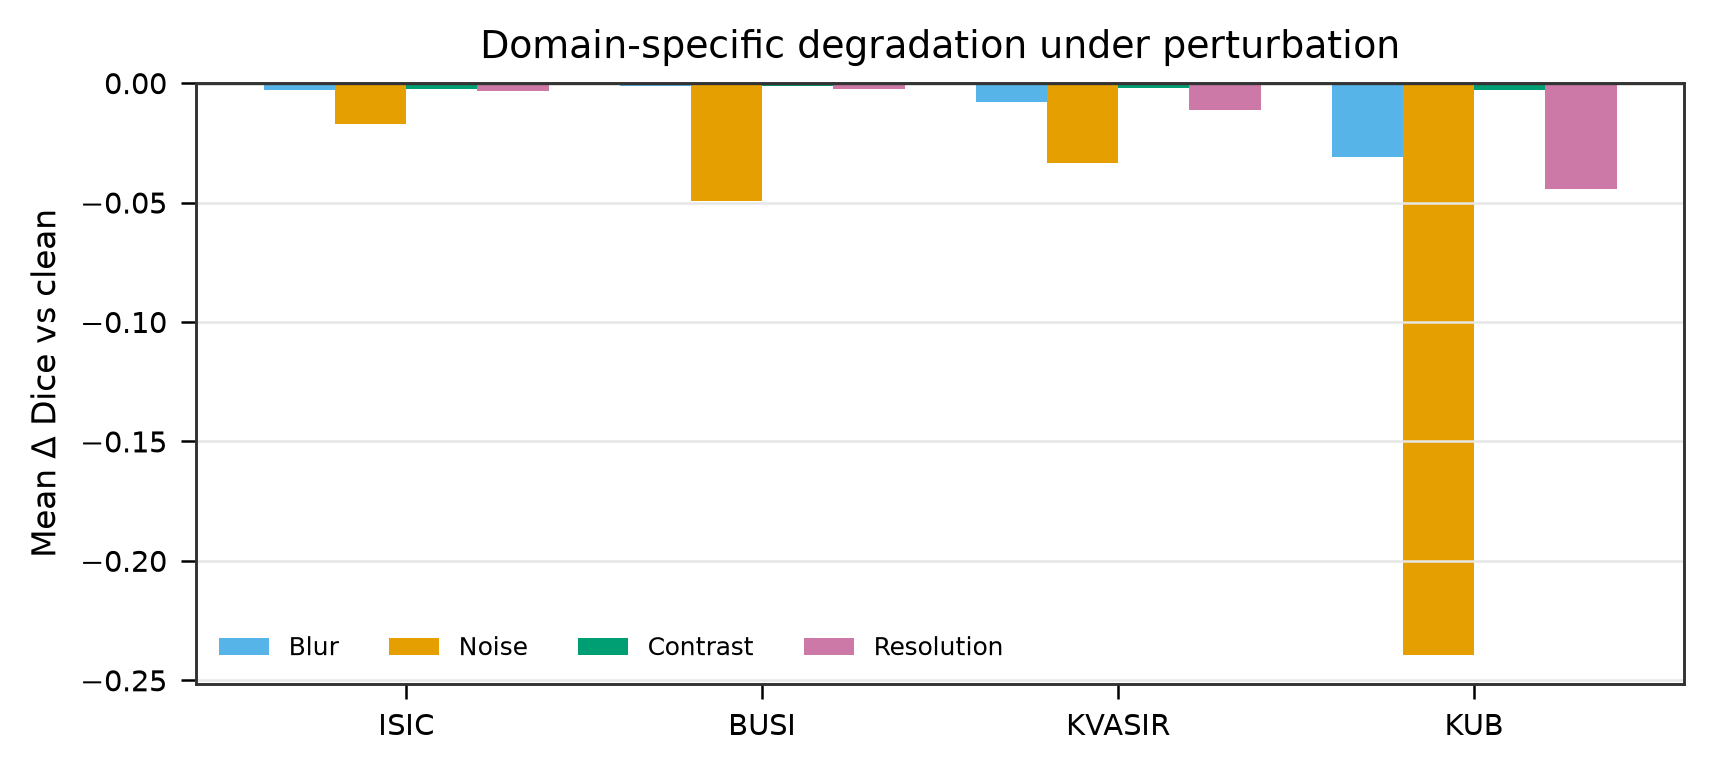

In [7]:

for f in ["external_evaluation/EXT01_external_dice",
          "external_evaluation/EXT03_stonefree_false_positive",
          "robustness/ROB01_perturbation_degradation",
          "robustness/ROB02_domain_degradation"]:
    display(Image(filename=str(FIGURES / f"{f}.png"), width=720))


In [8]:

# Negative control: enforcement must be real.
for name, verdict in GUARD.self_test():
    print(f"  {name:28s}: {verdict}")
assert all(v.startswith("blocked") for _, v in GUARD.self_test())
print("OK")


  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked
OK
